# Homework II - Part II: Programming
**Aprendizagem 2026/27**, Group 075

Dataset: `heart.csv` (284 patients, 9 input variables, target `outcome`: 1 = heart disease, 0 = no disease)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

df = pd.read_csv("heart.csv")
X = df.drop(columns="outcome")
y = df["outcome"]
print(X.shape)
print(y.value_counts())

(284, 9)
outcome
0    181
1    103
Name: count, dtype: int64


## 1. kNN and Naïve Bayes
Comparison between kNN ($k=5$) and Gaussian Naïve Bayes through 5-fold stratified CV (shuffle, `random_state=0`)


In [2]:
knn = KNeighborsClassifier(n_neighbors=5)
gnb = GaussianNB()

### 1a) Mean and standard deviation of accuracy and positive-class recall

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
knnScores = cross_validate(knn, X, y, cv=cv, scoring=["accuracy", "recall"])
gnbScores = cross_validate(gnb, X, y, cv=cv, scoring=["accuracy", "recall"])

results = pd.DataFrame({
    (name, metric): {
        "mean": score[f"test_{metric}"].mean(),
        "std":  score[f"test_{metric}"].std(),
        "min":  score[f"test_{metric}"].min(),
        "max":  score[f"test_{metric}"].max(),
    }
    for name, score in [("kNN", knnScores), ("Naive Bayes", gnbScores)]
    for metric in ["accuracy", "recall"]
}).T.round(3)
results

mean    std    min    max
kNN         accuracy  0.591  0.033  0.561  0.632
            recall    0.329  0.089  0.200  0.429
Naive Bayes accuracy  0.817  0.036  0.750  0.860
            recall    0.766  0.041  0.700  0.810

**Which is more stable?**

The Naïve Bayes classifier is more stable performance-wise: both models have practically the same accuracy standard deviation (~ 0.036), but kNN's recall varies much more across folds (std ~ 0.104, from 0.150 to 0.429) than Naïve Bayes's (std ~ 0.041).

### 1b) Same assessment with Min-Max scaling inside a pipeline

In [4]:
knnScaled = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=5))
gnbScaled = make_pipeline(MinMaxScaler(), GaussianNB())

knnScaledScores = cross_validate(knnScaled, X, y, cv=cv, scoring=["accuracy", "recall"])
gnbScaledScores = cross_validate(gnbScaled, X, y, cv=cv, scoring=["accuracy", "recall"])

resultsMinMax = pd.DataFrame({
    (name, metric): {
        "mean": score[f"test_{metric}"].mean(),
        "std":  score[f"test_{metric}"].std(),
        "min":  score[f"test_{metric}"].min(),
        "max":  score[f"test_{metric}"].max(),
    }
    for name, score in [("kNN", knnScaledScores), ("Naive Bayes", gnbScaledScores)]
    for metric in ["accuracy", "recall"]
}).T.round(3)
pd.concat({"Unscaled": results, "Min-Max": resultsMinMax}, axis=1)


Unscaled                      Min-Max                \
                         mean    std    min    max    mean    std    min   
kNN         accuracy    0.591  0.033  0.561  0.632   0.792  0.045  0.714   
            recall      0.329  0.089  0.200  0.429   0.630  0.080  0.500   
Naive Bayes accuracy    0.817  0.036  0.750  0.860   0.817  0.036  0.750   
            recall      0.766  0.041  0.700  0.810   0.766  0.041  0.700   

                             
                        max  
kNN         accuracy  0.842  
            recall    0.714  
Naive Bayes accuracy  0.860  
            recall    0.810

**Impact of scaling on each model:**

Min-Max scaling rescales each variable to the range [0, 1]. kNN classifies by Euclidean distance, the square root of the sum of the squared differences across all variables. Without scaling, variables with large ranges (`thalach`, `trestbps`, `age`) dominate the distance, and squaring the differences amplifies this, while informative variables with small ranges (`oldpeak`, `exercise_induce_angina`, `sex`) barely contribute. After scaling, all variables contribute comparably, so the nearest neighbours are more meaningful. This is visible in the results: kNN's accuracy rises from 0.588 to 0.792 and its recall nearly doubles, from 0.319 to 0.630, with recall also becoming more stable (std from 0.104 to 0.080).

On the other hand, Naïve Bayes's results are identical. GaussianNB fits an independent Gaussian to each variable in each class. Min-Max scaling is a linear transformation, $x' = (x - a)/b$, so the estimated means and standard deviations transform the same way ($\mu' = (\mu - a)/b$, $\sigma' = \sigma/b$). Each class's likelihood for that variable is multiplied by the same factor $1/b$, which cancels when the posteriors are compared, so the predictions do not change. Even after scaling, Naïve Bayes still outperforms kNN in both accuracy and recall.

## 2. kNN with varying $k$
Stratified 70-30 split (`random_state=0`), Min-Max scaling, $k \in \{1, 5, 10, 15, 20, 25\}$, uniform and distance weights.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=0)

kValues = [1, 5, 10, 15, 20, 25]
rows = []
for k in kValues:
    uniformModel = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=k, weights="uniform"))
    distanceModel = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=k, weights="distance"))
    uniformModel.fit(X_train, y_train)
    distanceModel.fit(X_train, y_train)

    rows.append({
        "k": k,
        "uniform_train_accuracy": accuracy_score(y_train, uniformModel.predict(X_train)),
        "uniform_test_accuracy": accuracy_score(y_test, uniformModel.predict(X_test)),
        "distance_train_accuracy": accuracy_score(y_train, distanceModel.predict(X_train)),
        "distance_test_accuracy": accuracy_score(y_test, distanceModel.predict(X_test)),
    })

kResults = pd.DataFrame(rows).set_index("k").round(3)
kResults


,uniform_train_accuracy,uniform_test_accuracy,distance_train_accuracy,distance_test_accuracy
k,,,,
1,1.000,0.709,1.0,0.709
5,0.833,0.826,1.0,0.826
10,0.823,0.860,1.0,0.826
15,0.798,0.860,1.0,0.814
20,0.793,0.872,1.0,0.837
25,0.783,0.884,1.0,0.872


### 2a) Train and test accuracies

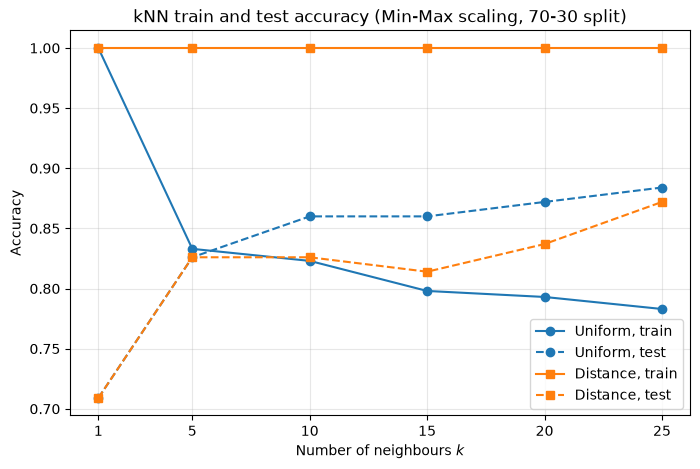

In [6]:
kTable = kResults

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(kTable.index, kTable["uniform_train_accuracy"], marker="o", color="tab:blue", label="Uniform, train")
ax.plot(kTable.index, kTable["uniform_test_accuracy"], marker="o", color="tab:blue", linestyle="--", label="Uniform, test")
ax.plot(kTable.index, kTable["distance_train_accuracy"], marker="s", color="tab:orange", label="Distance, train")
ax.plot(kTable.index, kTable["distance_test_accuracy"], marker="s", color="tab:orange", linestyle="--", label="Distance, test")
ax.set_xticks(kTable.index)
ax.set_xlabel("Number of neighbours $k$")
ax.set_ylabel("Accuracy")
ax.set_title("kNN train and test accuracy (Min-Max scaling, 70-30 split)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()


### 2b) Impact of $k$ on generalization, trade-offs and optimal $k$

- **Small $k$ (1):** Each training patient is its own nearest neighbour, so it is always classified with its own label: the 100% training accuracy is guaranteed by construction. Testing accuracy is only 70.9%, a gap of ~29 percentage points. This is clear evidence of overfitting: the decision boundary follows every individual training patient, including potential outliers, and doesn't generalise well to unseen patients.
- **Intermediate values (5, 10, 15):** With uniform weights, training accuracy drops (83.3% / 82.3% / 79.8%) while testing accuracy rises (82.6% / 86.0% / 86.0%). Voting over several neighbours smooths the decision boundary and makes predictions less sensitive to individual patients and noise, and the train-test gap shortens considerably.
- **Large values (20, 25):** Training accuracy keeps falling (79.3% / 78.3%), while testing accuracy reaches its maximum (87.2% / 88.4%). Within the tested range there is no sign of underfitting yet, since testing accuracy has not started to fall.

- $k$ controls how closely kNN follows the training data. A small $k$ gives a flexible, irregular decision boundary, whose predictions change with the specific patients that end up in the neighbourhood, which leads to overfitting. A large $k$ averages over more patients, giving a smoother and more stable boundary, but if it grows too much the neighbours become less similar to the patient being classified, which leads to underfitting. In the plot, only the first effect is visible: training accuracy goes down as $k$ grows, while testing accuracy goes up.

- **Uniform vs distance weights:** with distance weights, training accuracy is 100% for every $k$, because each training patient is its own nearest neighbour at distance 0 and decides the vote alone. Training accuracy is therefore not informative about overfitting for these models. Their testing accuracy is equal to or lower than with uniform weights for every $k$ (e.g. 81.4% vs 86.0% for $k=15$): the closest neighbours dominate the vote, so the model behaves like one with a smaller effective $k$ and smooths less.

- **Optimal $k$:** with uniform weights, $k=25$ has the highest testing accuracy (88.4%), but we propose a range, $k \in [10, 25]$ with uniform weights, instead of a single value. The differences within this range are very small: on 86 test patients, one patient corresponds to ~1.2 p.p., so 86.0% vs 88.4% is only two patients. Moreover, the best value is at the edge of the tested range, so we cannot tell whether a larger $k$ would keep improving or start to underfit.

- **Limitations:** the conclusions are based on a single train-test split. As explained above, a larger $k$ makes the model follow the training data less closely and dilutes the vote of each training patient for itself, so training and testing accuracy are expected to become similar. However, with this split, testing accuracy clearly surpasses training accuracy for $k \geq 10$ (by ~10 p.p. at $k=25$). This shows how much the results depend on this particular split, whose test set appears to be easier than average. Cross-validation would give a more reliable estimate of generalisation.

Moreover, accuracy alone does not distinguish between false negatives and false positives. In heart disease diagnosis, recall would be important to determine the best model, since a false negative means a sick patient goes undiagnosed.

## 3. LIME explanations
Pipelines of 1b) trained on the split of exercise 2.

Changes to the given `explain()` function: `X_train` is passed as a NumPy array (`X_train.values`), since LIME does not accept DataFrames, and LIME's samples are converted to a DataFrame with the original column names before calling `predict_proba`, only to avoid sklearn's feature-name warnings (the pipelines were fitted on a DataFrame); the predictions, and therefore the explanations, are unchanged.

In [7]:
from lime.lime_tabular import LimeTabularExplainer

features = X.columns.tolist()

def explain(model, x, seed=0, num_samples=5000):
    explainer = LimeTabularExplainer(
        X_train.values, feature_names=features,
        class_names=["no disease", "disease"],
        mode="classification", random_state=seed)
    return explainer.explain_instance(
        x, lambda Z: model.predict_proba(pd.DataFrame(Z, columns=features)),
        num_features=5, num_samples=num_samples)

In [8]:
knnScaled.fit(X_train, y_train)
gnbScaled.fit(X_train, y_train)

predictions = pd.DataFrame({
    "true": y_test.values,
    "knn": knnScaled.predict(X_test),
    "gnb": gnbScaled.predict(X_test),
})
print(f"kNN test accuracy: {accuracy_score(predictions['true'], predictions['knn']):.3f}")
print(f"NB test accuracy:  {accuracy_score(predictions['true'], predictions['gnb']):.3f}")
predictions.head(10)

kNN test accuracy: 0.826
NB test accuracy:  0.849


,true,knn,gnb
0,0,0,0
1,1,1,1
2,0,0,0
3,1,0,0
4,0,1,0
5,0,1,1
6,0,0,0
7,1,1,1
8,1,0,1
9,0,0,0


### 3a) First test patient with heart disease correctly classified by both models

Test patient 1: {'age': 52.0, 'sex': 1.0, 'chest_pain': 4.0, 'trestbps': 112.0, 'fasting_blood_sugar': 0.0, 'restecg': 1.0, 'thalach': 96.0, 'exercise_induce_angina': 1.0, 'oldpeak': 1.0}

kNN: P(disease) = 0.600, fidelity (R^2) = 0.537
  0.00 < exercise_induce_angina <= 1.00    +0.290
  3.00 < chest_pain <= 4.00                +0.265
  fasting_blood_sugar <= 0.00              -0.255
  0.00 < sex <= 1.00                       +0.212
  thalach <= 120.00                        +0.032

Naive Bayes: P(disease) = 0.983, fidelity (R^2) = 0.454
  fasting_blood_sugar <= 0.00              -0.676
  0.00 < exercise_induce_angina <= 1.00    +0.374
  0.00 < sex <= 1.00                       +0.266
  3.00 < chest_pain <= 4.00                +0.168
  restecg > 0.00                           -0.128


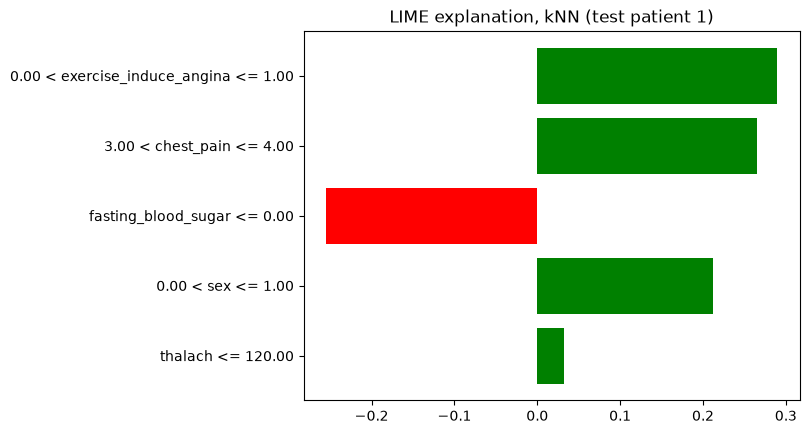

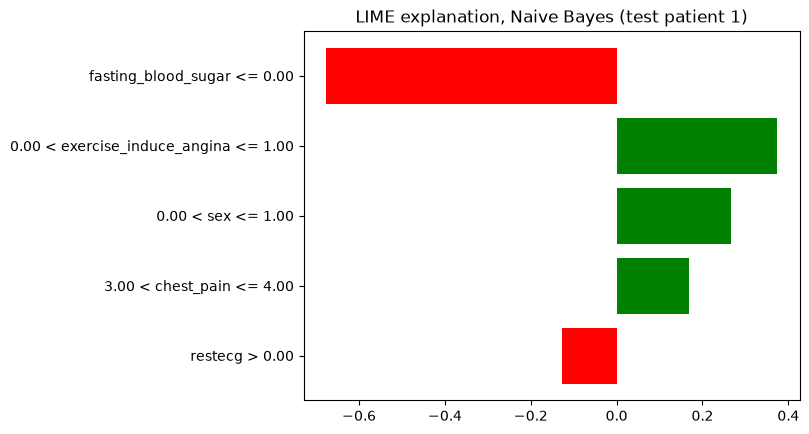

In [9]:
p = predictions.index[(predictions["true"] == 1) & (predictions["knn"] == 1) & (predictions["gnb"] == 1)][0]
x = X_test.values[p]
print(f"Test patient {p}:", X_test.iloc[p].to_dict())

expKnn = explain(knnScaled, x)
expGnb = explain(gnbScaled, x)

for name, model, exp in [("kNN", knnScaled, expKnn), ("Naive Bayes", gnbScaled, expGnb)]:
    print(f"\n{name}: P(disease) = {model.predict_proba(X_test.iloc[[p]])[0, 1]:.3f}, fidelity (R^2) = {exp.score:.3f}")
    for condition, weight in exp.as_list():
        print(f"  {condition:40s} {weight:+.3f}")
    fig = exp.as_pyplot_figure()
    fig.axes[0].set_title(f"LIME explanation, {name} (test patient {p})")
plt.show()


In [10]:
# Explanations with all 9 variables: rank and weight of thalach and restecg
for name, model in [("kNN", knnScaled), ("Naive Bayes", gnbScaled)]:
    explainer = LimeTabularExplainer(
        X_train.values, feature_names=features,
        class_names=["no disease", "disease"],
        mode="classification", random_state=0)
    full = explainer.explain_instance(
        x, lambda Z: model.predict_proba(pd.DataFrame(Z, columns=features)),
        num_features=9, num_samples=5000)
    for rank, (condition, weight) in enumerate(full.as_list(), start=1):
        if "thalach" in condition or "restecg" in condition:
            print(f"{name}: {condition:20s} rank {rank} of 9, weight {weight:+.3f}")

# restecg: distribution per class and NB prediction for each value
nb = gnbScaled[-1]
print()
print(pd.crosstab(X_train["restecg"], y_train))
for v in [0, 1, 2]:
    xRestecg = X_test.iloc[[p]].copy()
    xRestecg["restecg"] = v
    print(f"NB P(disease) for patient {p} with restecg = {v}: {gnbScaled.predict_proba(xRestecg)[0, 1]:.3f}")

kNN: thalach <= 120.00    rank 5 of 9, weight +0.032
kNN: restecg > 0.00       rank 6 of 9, weight -0.014
Naive Bayes: restecg > 0.00       rank 5 of 9, weight -0.129
Naive Bayes: thalach <= 120.00    rank 6 of 9, weight +0.108

outcome   0   1
restecg        
0        99  62
1        23  10
2         4   0
NB P(disease) for patient 1 with restecg = 0: 0.998
NB P(disease) for patient 1 with restecg = 1: 0.983
NB P(disease) for patient 1 with restecg = 2: 0.090


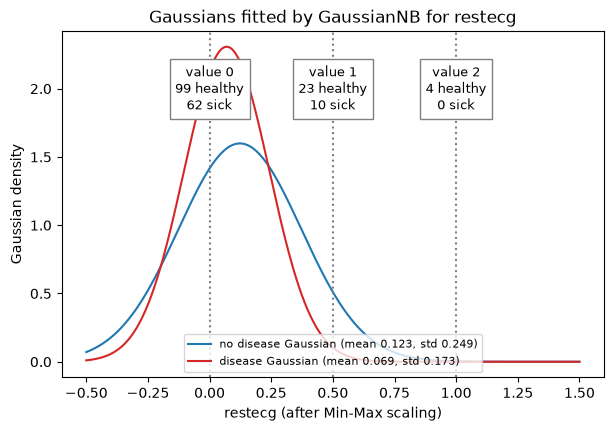

In [11]:
# Gaussians fitted by GaussianNB for a variable, with the training counts of each value
def plotGaussians(variable):
    nb = gnbScaled[-1]
    j = features.index(variable)
    values = np.sort(X_train[variable].unique())
    scaledValues = (values - X_train[variable].min()) / (X_train[variable].max() - X_train[variable].min())
    grid = np.linspace(-0.5, 1.5, 500)
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for c, label, color in [(0, "no disease", "tab:blue"), (1, "disease", "tab:red")]:
        mean, std = nb.theta_[c, j], np.sqrt(nb.var_[c, j])
        density = np.exp(-(grid - mean) ** 2 / (2 * std ** 2)) / (std * np.sqrt(2 * np.pi))
        ax.plot(grid, density, color=color, label=f"{label} Gaussian (mean {mean:.3f}, std {std:.3f})")
    ymax = ax.get_ylim()[1]
    for v, sv in zip(values, scaledValues):
        counts = [((X_train[variable] == v) & (y_train == c)).sum() for c in (0, 1)]
        ax.axvline(sv, color="grey", linestyle=":")
        ax.text(sv, ymax * 0.9, f"value {v}\n{counts[0]} healthy\n{counts[1]} sick",
                ha="center", va="top", fontsize=9, bbox=dict(facecolor="white", edgecolor="grey"))
    ax.set_title(f"Gaussians fitted by GaussianNB for {variable}")
    ax.set_xlabel(f"{variable} (after Min-Max scaling)")
    ax.set_ylabel("Gaussian density")
    ax.legend(loc="lower center", fontsize=8)
    plt.show()

plotGaussians("restecg")

**Do the two models rely on the same evidence?**

Mostly, yes. Both explanations share the same four strongest conditions: exercise-induced angina (`exercise_induce_angina` = 1), asymptomatic chest pain (`chest_pain` = 4) and being male (`sex` = 1) push the prediction towards disease, while a normal fasting blood sugar (`fasting_blood_sugar` = 0) pushes it away. Only the fifth condition differs: `thalach <= 120` for kNN (+0.032) and `restecg > 0` for Naïve Bayes (-0.128).

This difference only concerns the last place of the explanation. With all 9 variables, `thalach` and `restecg` take the fifth and sixth places in both models, with relatively small weights, and the cut at 5 hides whichever comes sixth.

The order differs because Naïve Bayes exaggerates the effect of `restecg`: it is a categorical variable, mostly 0 across patients, which does not fit a Gaussian distribution well. Non-zero values are less common among sick patients, and the 4 patients with value 2 are all healthy, meaning the disease Gaussian ends up narrower. Naïve Bayes therefore treats non-zero values as evidence against disease, which becomes very strong the further the value is from 0 (see P(disease) for different values). kNN, on the other hand, makes no assumption about the shape of the data: it predicts by the vote of the real training patients closest to each sample. Since `restecg` is only weakly related to the outcome in the training data (27% of patients with `restecg` > 0 have heart disease, vs 39% with `restecg` = 0, a difference based on only 37 patients with non-zero values), moving a sample towards patients with a different `restecg` does not consistently change the share of sick neighbours, and its weight stays small.

Moreover, LIME only distinguishes `restecg <= 0` from `restecg > 0`, merging values 1 and 2, so the weight of `restecg > 0` partly reflects the extreme response to value 2, which this patient (`restecg` = 1) does not have.

Overall, the models differ more in confidence than in evidence: based on mostly the same conditions, kNN gives P(disease) = 0.60 and Naïve Bayes 0.98.

We kept the 5 variables of the given function for the requested explanations; the ones with all 9 variables are only used as a check.


outcome                0   1
fasting_blood_sugar         
0                    123  62
1                      3  10

Likelihood ratio disease / no disease at 1: 1.59e+07
NB P(disease) for patient 1: 0.982640, with fasting_blood_sugar = 1: 1.000000


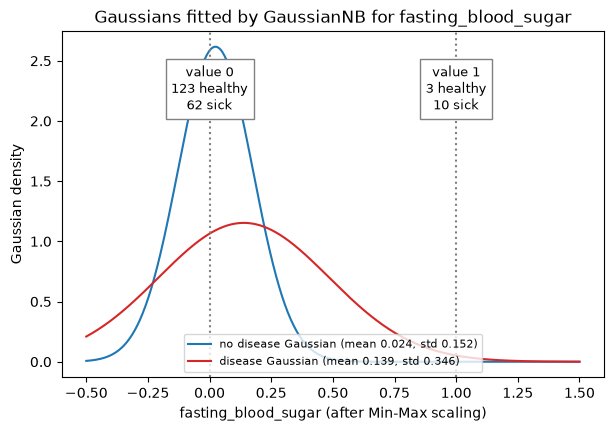

,mean (theta_),variance (var_),std,likelihood at 0,likelihood at 1
no disease,0.023810,0.023243,0.152455,2.585063,3.271377e-09
disease,0.138889,0.119599,0.345831,1.064199,5.196774e-02


In [12]:
# Gaussians estimated by NB for fasting_blood_sugar (already in [0, 1], so Min-Max leaves it unchanged)
nb = gnbScaled[-1]
fbs = features.index("fasting_blood_sugar")
mean, var = nb.theta_[:, fbs], nb.var_[:, fbs]
gaussian = lambda v: np.exp(-(v - mean) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)
fbsTable = pd.DataFrame({
    "mean (theta_)": mean,
    "variance (var_)": var,
    "std": np.sqrt(var),
    "likelihood at 0": gaussian(0),
    "likelihood at 1": gaussian(1),
}, index=["no disease", "disease"])
print()
print(pd.crosstab(X_train["fasting_blood_sugar"], y_train))
print(f"\nLikelihood ratio disease / no disease at 1: {gaussian(1)[1] / gaussian(1)[0]:.3g}")

xFlip = X_test.iloc[[p]].copy()
xFlip["fasting_blood_sugar"] = 1
print(f"NB P(disease) for patient {p}: {gnbScaled.predict_proba(X_test.iloc[[p]])[0, 1]:.6f}, "
      f"with fasting_blood_sugar = 1: {gnbScaled.predict_proba(xFlip)[0, 1]:.6f}")
plotGaussians("fasting_blood_sugar")
fbsTable

**Why Naïve Bayes gives `fasting_blood_sugar` a much larger weight:**

Naïve Bayes exaggerates `fasting_blood_sugar` in the same way as `restecg` above, but much more strongly. `fasting_blood_sugar` is binary, and only 13 of the 198 training patients have value 1 (3 without and 10 with heart disease). GaussianNB nonetheless models it with a Gaussian in each class (Min-Max scaling leaves it unchanged, since it is already in [0, 1]):

| Class | Mean (`theta_`) | Variance (`var_`) | Std |
|---|---|---|---|
| No disease | 0.024 | 0.023 | 0.152 |
| Disease | 0.139 | 0.120 | 0.346 |

Since almost all healthy patients have value 0, the no-disease Gaussian is very narrow (plot above). A value of 1 lies (1 - 0.024) / 0.152 ~ 6.4 standard deviations from the no-disease mean, but only ~2.5 from the disease mean. The likelihoods at 1 are therefore ~$3.3 \times 10^{-9}$ (no disease) and ~0.052 (disease), a ratio of ~$1.6 \times 10^{7}$ in favour of disease, while in the training data the actual ratio is only (10/72) / (3/126) ~ 5.8. In gnb's calculations, a factor this large overrides every other variable.

When LIME perturbs the patient, every artificial sample with `fasting_blood_sugar` = 1 gets P(disease) ~1, whatever its other values. The linear model therefore attributes a large weight to the condition `fasting_blood_sugar <= 0` (-0.68). kNN has no such probabilistic model: a sample with `fasting_blood_sugar` = 1 only moves closer to the training patients with that value, and its prediction is still a vote among its 5 nearest neighbours, which also depends on the other variables. Its effect is therefore smaller and less systematic (-0.26).

### 3b) First false negative for at least one model

Test patient 3: {'age': 39.0, 'sex': 1.0, 'chest_pain': 4.0, 'trestbps': 110.0, 'fasting_blood_sugar': 0.0, 'restecg': 0.0, 'thalach': 150.0, 'exercise_induce_angina': 0.0, 'oldpeak': 0.0}
Predictions: kNN = 0, Naive Bayes = 0 (true class = 1)

kNN: P(disease) = 0.400, fidelity (R^2) = 0.572, LIME's prediction for the patient = 0.401
  exercise_induce_angina <= 0.00           -0.288
  3.00 < chest_pain <= 4.00                +0.271
  fasting_blood_sugar <= 0.00              -0.249
  0.00 < sex <= 1.00                       +0.207
  oldpeak <= 0.00                          -0.123

Naive Bayes: P(disease) = 0.049, fidelity (R^2) = 0.634, LIME's prediction for the patient = 0.249
  fasting_blood_sugar <= 0.00              -0.684
  oldpeak <= 0.00                          -0.389
  exercise_induce_angina <= 0.00           -0.370
  0.00 < sex <= 1.00                       +0.252
  3.00 < chest_pain <= 4.00                +0.156


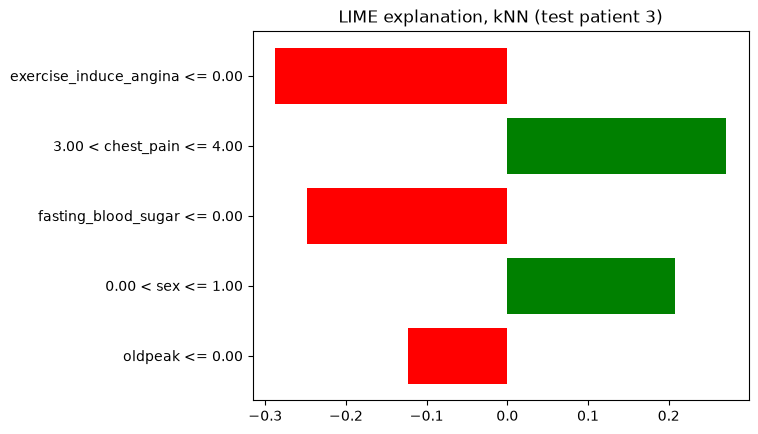

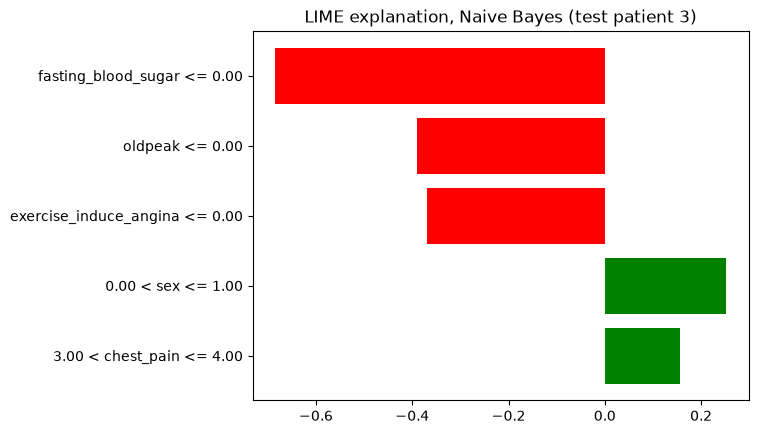


Disease rate in training: chest_pain = 4: 0.66, other chest pain types: 0.17

Naive Bayes, ratio disease / no disease at this patient's values:
age                       0.53
sex                       2.22
chest_pain                3.32
trestbps                  0.69
fasting_blood_sugar       0.41
restecg                   1.50
thalach                   0.65
exercise_induce_angina    0.31
oldpeak                   0.26

Training patients with the same profile (male, chest_pain = 4, no angina, oldpeak = 0, normal blood sugar):
outcome
no disease    12
disease       12


In [13]:
# Different names from 3a, since 3c uses the patient of 3a again
q = predictions.index[(predictions["true"] == 1) & ((predictions["knn"] == 0) | (predictions["gnb"] == 0))][0]
xFn = X_test.values[q]
print(f"Test patient {q}:", X_test.iloc[q].to_dict())
print(f"Predictions: kNN = {predictions['knn'][q]}, Naive Bayes = {predictions['gnb'][q]} (true class = 1)")

expKnnFn = explain(knnScaled, xFn)
expGnbFn = explain(gnbScaled, xFn)

for name, model, exp in [("kNN", knnScaled, expKnnFn), ("Naive Bayes", gnbScaled, expGnbFn)]:
    print(f"\n{name}: P(disease) = {model.predict_proba(X_test.iloc[[q]])[0, 1]:.3f}, fidelity (R^2) = {exp.score:.3f}, "
          f"LIME's prediction for the patient = {exp.local_pred[0]:.3f}")
    for condition, weight in exp.as_list():
        print(f"  {condition:40s} {weight:+.3f}")
    fig = exp.as_pyplot_figure()
    fig.axes[0].set_title(f"LIME explanation, {name} (test patient {q})")
plt.show()

print(f"\nDisease rate in training: chest_pain = 4: {y_train[X_train['chest_pain'] == 4].mean():.2f}, "
      f"other chest pain types: {y_train[X_train['chest_pain'] != 4].mean():.2f}")

# Naive Bayes's own calculation for this patient: ratio between the disease and no-disease Gaussians at each value
nb = gnbScaled[-1]
xScaled = gnbScaled[0].transform(X_test.iloc[[q]])[0]
density = lambda v, c: np.exp(-(v - nb.theta_[c]) ** 2 / (2 * nb.var_[c])) / np.sqrt(2 * np.pi * nb.var_[c])
ratios = pd.Series(density(xScaled, 1) / density(xScaled, 0), index=features)
print("\nNaive Bayes, ratio disease / no disease at this patient's values:")
print(ratios.round(2).to_string())

# Training patients with the same profile as this patient
sameProfile = ((X_train["sex"] == 1) & (X_train["chest_pain"] == 4) & (X_train["exercise_induce_angina"] == 0)
               & (X_train["oldpeak"] == 0) & (X_train["fasting_blood_sugar"] == 0))
print("\nTraining patients with the same profile (male, chest_pain = 4, no angina, oldpeak = 0, normal blood sugar):")
print(y_train[sameProfile].value_counts().rename({0: "no disease", 1: "disease"}).to_string())

**Which conditions pushed the prediction towards the wrong class?**

Test patient 3 is the first false negative, and it is misclassified by both models: kNN gives P(disease) = 0.40 and Naïve Bayes 0.05. The patient is a 39-year-old man with asymptomatic chest pain (`chest_pain` = 4), but otherwise normal values: no exercise-induced angina, no ST depression (`oldpeak` = 0) and normal fasting blood sugar. In both explanations, these three normal values push the prediction towards no disease. Being male and the asymptomatic chest pain push towards disease, but not enough to compensate.

**Fidelity**

The fidelity is moderate for both explanations: $R^2$ = 0.572 for kNN and 0.634 for Naïve Bayes, meaning the linear model only reproduces part of how each model's output varies around the patient. For kNN, the prediction of LIME's linear model at the patient matches the model's (0.401 vs 0.40), but for Naïve Bayes it predicts 0.249, while the model gives 0.049, so the weights do not add up to the actual prediction.

**Can the explanation be trusted?**

Only partially. With moderate fidelity, it is an approximate description of why each model predicted no disease. Some examples where it does not match the models:

- **Naïve Bayes, the prediction:** as reported above, LIME's linear model predicts P(disease) = 0.249 for this patient, while the model gives 0.049, so the weights do not add up to the actual prediction.
- **Naïve Bayes, the main reason:** LIME ranks `fasting_blood_sugar <= 0` first (-0.684), mostly because of how strongly the model would react to a value of 1 (as seen in 3a). In the model's own calculation, the patient's normal blood sugar lowers the odds of disease by 59% (ratio 0.41), less than `oldpeak` = 0 (74%, ratio 0.26) or the absence of exercise-induced angina (69%, ratio 0.31), so a clinician would be misled about the model's main reason.
- **kNN:** its output only changes in steps of 0.2 (a vote among 5 neighbours), which a linear model can only approximate, which partly explains its fidelity of 0.572.

**How could a clinician have suspected the error?**

- kNN's P(disease) of 0.40 is close to the 0.5 threshold, so its prediction is not a confident one.
- The explanation shows that asymptomatic chest pain, the condition in this explanation that is most associated with disease (66% of training patients with `chest_pain` = 4 have heart disease, vs 17% with other types), is outweighed only by normal values. A clinician would know that these normal findings do not rule out heart disease in a man with asymptomatic chest pain, and the training data agree (12 vs 12 for this profile), so a confident prediction of no disease, especially Naïve Bayes's 0.05, should raise suspicion.
- For Naïve Bayes, the explanation puts a normal fasting blood sugar first, which a clinician would recognise as a weak reason to rule out heart disease (62 of the 72 sick training patients also have it).

### 3c) Explanation stability
kNN model, patient of 3a), seeds 0 to 9, `num_samples` ∈ {500, 5000}

In [14]:
# 10 LIME explanations of the kNN prediction for the patient of 3a (x), with seeds 0 to 9
stability = {}
orders = {}
for numSamples in [500, 5000]:
    rows = []
    orders[numSamples] = []
    for seed in range(10):
        exp = explain(knnScaled, x, seed=seed, num_samples=numSamples)
        top5 = exp.as_map()[1]   # (variable index, weight) of the top-5, in LIME's order
        orders[numSamples].append(tuple(features[j] for j, _ in top5))
        for rank, (j, weight) in enumerate(top5, start=1):
            rows.append({"seed": seed, "variable": features[j], "rank": rank, "weight": weight})
    runs = pd.DataFrame(rows)
    stability[numSamples] = runs.groupby("variable").agg(
        times_in_top5=("seed", "count"),
        mean_weight=("weight", "mean"),
        std_weight=("weight", lambda w: w.std(ddof=0) if len(w) > 1 else np.nan),   # undefined if it appears only once
        ranks=("rank", lambda r: sorted(set(r))),
    ).sort_values(["times_in_top5", "mean_weight"], key=abs, ascending=False)

for numSamples in [500, 5000]:
    print(f"\nnum_samples = {numSamples}: {len(set(orders[numSamples]))} different top-5 orders in 10 explanations")
    print(stability[numSamples].round(3).to_string())


num_samples = 500: 9 different top-5 orders in 10 explanations
                        times_in_top5  mean_weight  std_weight      ranks
variable                                                                 
exercise_induce_angina             10        0.278       0.025     [1, 2]
chest_pain                         10        0.272       0.020  [1, 2, 3]
sex                                10        0.207       0.017     [3, 4]
fasting_blood_sugar                10       -0.205       0.038  [2, 3, 4]
thalach                             3        0.034       0.014        [5]
restecg                             3       -0.029       0.003        [5]
oldpeak                             2       -0.029       0.008        [5]
trestbps                            1        0.039         NaN        [5]
age                                 1        0.033         NaN        [5]

num_samples = 5000: 5 different top-5 orders in 10 explanations
                        times_in_top5  mean_weight  std_w

**Which parts of a single LIME explanation can be trusted, and in which situations can they not?**

With both settings, the same four variables appear in all 10 explanations (`exercise_induce_angina`, `chest_pain`, `fasting_blood_sugar` and `sex`), while the fifth place changes between seeds: 5 different variables with 500 samples and 4 with 5000. With 5000 samples, the standard deviations of the weights are ~3 times smaller (e.g. 0.025 vs 0.008 for `exercise_induce_angina`), and the number of different top-5 orders drops from 9 to 5.

- **Variables in the top-5:** the variables with large weights can be trusted, since they appear in every explanation, even with 500 samples. The variables with small weights cannot: the candidates for the fifth place have weights within ~0.01 to 0.02 of each other, comparable to how much the weights vary between seeds (standard deviations of up to 0.038 with 500 samples and 0.012 with 5000), so which of them takes the fifth place depends on the seed.
- **Order:** it can only be trusted when the weights are clearly apart. With 500 samples, 9 of the 10 explanations have a different order. With 5000, `exercise_induce_angina` is always first and `sex` always fourth, but `chest_pain` and `fasting_blood_sugar` swap places, since their absolute weights (0.256 vs -0.241 on average) differ by little more than their standard deviations (0.006 and 0.012).
- **Weights:** the signs and approximate magnitudes of the top-4 weights can be trusted even with 500 samples, since their standard deviations (up to 0.038) are small compared with the weights themselves. However, they are comparable to the differences between weights, which is why the order changes between seeds. The exact values are more reliable with 5000 samples, where the standard deviations are at most 0.012.

Finally, stability is not the same as fidelity: increasing `num_samples` makes the explanation more stable, but not more faithful to the model, since the linear model still only partially imitates it ($R^2$ = 0.537 in 3a), and a stable explanation can still be misleading, as with `fasting_blood_sugar` in 3b.

## 4. Deployment choice: kNN or Naïve Bayes

We would deploy **Naïve Bayes**:

- **Recall:** in a hospital, missing a sick patient is the most costly error. Naïve Bayes has a higher recall (0.766) than kNN, both without scaling (0.319) and with Min-Max scaling (0.630).
- **Accuracy:** it is also more accurate (0.817, vs 0.588 and 0.792 for kNN). Moreover, these results do not depend on preprocessing, since they are identical with and without scaling, while kNN's performance depends heavily on it.

Two caveats: in exercise 2, kNN with larger $k$ (10 to 25) reached a testing accuracy of 0.860 to 0.884, above Naïve Bayes's 0.849 on the same split (although this is based on a single split and on accuracy only). And, as seen in exercise 3, Naïve Bayes's Gaussians exaggerate the effect of rare values of binary and categorical variables (`fasting_blood_sugar`, `restecg`), which can make it overconfident: in 3b, it gave P(disease) = 0.05 to a patient whose profile is evenly split (12 vs 12) in the training data.

**Would LIME explanations be enough to justify deploying kNN?** No. In 3b, kNN's explanation of the false negative was reasonably faithful (its linear model predicts 0.401 for the patient, vs the model's 0.40) and clinically plausible (no angina, no ST depression and normal blood sugar against asymptomatic chest pain), yet the prediction was wrong. LIME explains what the model does, not whether it is right, so a convincing explanation cannot make up for kNN's lower recall, i.e. for the sick patients it would miss.